# Multilingual RAG Results and Visualizations



## Imports & Configs

In [11]:
from __future__ import annotations

import re
import warnings
from pathlib import Path
from typing import Sequence

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from sklearn.metrics import cohen_kappa_score, confusion_matrix
from tqdm.auto import tqdm
from IPython.display import display

warnings.filterwarnings("ignore", category=RuntimeWarning)

In [12]:
ROOT = Path.cwd()
if not (ROOT / "data" / "judge step").exists() and (ROOT.parent / "data" / "judge step").exists():
    ROOT = ROOT.parent

JUDGE_DIR = ROOT / "data" / "judge step"
OUTPUT_DIR = ROOT / "results" / "multilingual_judge_analysis"
FIGURE_DIR = OUTPUT_DIR / "figures"
TABLE_DIR = OUTPUT_DIR / "tables"

FIGURE_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

N_BOOTSTRAP = 2000
RANDOM_SEED = 42
CI_LEVEL = 0.95
CLUSTER_COL = "query_id"

VALID_LABELS = ["ABSTAIN", "INCORRECT", "CORRECT"]
DIFFICULTY_ORDER = ["easy", "medium", "hard"]

print("Repository root:", ROOT)
print("Judge directory:", JUDGE_DIR)
print("Output directory:", OUTPUT_DIR)


Repository root: /Users/martasumyk/Desktop/Paper/rag-uncertainty-eval
Judge directory: /Users/martasumyk/Desktop/Paper/rag-uncertainty-eval/data/judge step
Output directory: /Users/martasumyk/Desktop/Paper/rag-uncertainty-eval/results/multilingual_judge_analysis


In [13]:
LANGUAGE_NAMES = {
    "ar": "Arabic", "de": "German", "en": "English", "es": "Spanish",
    "fa": "Persian", "fi": "Finnish", "fr": "French", "hi": "Hindi",
    "id": "Indonesian", "ja": "Japanese", "ko": "Korean",
    "ru": "Russian", "th": "Thai", "zh": "Chinese",
}

## Load data

In [14]:
def infer_metadata(path: Path, df: pd.DataFrame) -> dict[str, str]:
    filename = path.stem.lower()
    judge_provider = path.parent.name.lower()

    if "claude" in filename:
        generator = "Claude Sonnet 4"
    elif "gemini" in filename:
        generator = "Gemini 3.1 Flash-Lite"
    elif "gemma" in filename:
        generator = "Gemma 4 26B"
    elif "gpt54mini" in filename or "gpt5.4" in filename:
        generator = "GPT-5.4-mini"
    elif "qwen" in filename:
        generator = "Qwen 3.6 27B"
    elif "generation_model" in df.columns and df["generation_model"].notna().any():
        generator = str(df["generation_model"].dropna().iloc[0])
    else:
        generator = path.stem

    if "prompt_variant" in df.columns and df["prompt_variant"].notna().any():
        prompt = str(df["prompt_variant"].dropna().iloc[0]).lower()
    else:
        prompt = "advanced" if "advanced" in filename else "simple"

    if "context_mode" in df.columns and df["context_mode"].notna().any():
        context = str(df["context_mode"].dropna().iloc[0]).lower()
    elif "distractor_plus_gold" in filename:
        context = "distractor_plus_gold"
    elif "answer_with_distractor_and_gold" in df.columns:
        context = "distractor_plus_gold"
    else:
        context = "distractor"

    judge_name = {
        "openai": "GPT-5.4-mini",
        "gemini": "Gemini 3.1 Flash-Lite",
        "qwen": "Qwen 3.6 27B",
    }.get(judge_provider, judge_provider)

    return {
        "judge_model": judge_name,
        "judge_provider": judge_provider,
        "generation_model_clean": generator,
        "prompt_variant_clean": prompt,
        "context_mode_clean": context,
        "source_file": path.name,
        "source_path": str(path.relative_to(ROOT)),
    }


In [ ]:
csv_paths = sorted(JUDGE_DIR.glob("*/*.csv"))
if not csv_paths:
    raise FileNotFoundError(f"No judged CSVs found under {JUDGE_DIR}")

frames = []
for path in tqdm(csv_paths, desc="Loading judged CSVs"):
    part = pd.read_csv(path)
    for key, value in infer_metadata(path, part).items():
        part[key] = value
    frames.append(part)

results = pd.concat(frames, ignore_index=True, sort=False)

results["judge_label_clean"] = results["judge_label"].astype("string").str.strip().str.upper()
results["language"] = results["language"].astype(str).str.strip().str.lower()
results["language_name"] = results["language"].map(LANGUAGE_NAMES).fillna(results["language"])
results["difficulty_clean"] = results["difficulty"].astype(str).str.strip().str.lower()
results["generation_experiment"] = (
    results["generation_model_clean"] + " | "
    + results["prompt_variant_clean"] + " | "
    + results["context_mode_clean"]
)

print("CSV files:", len(csv_paths))
print("Combined rows:", f"{len(results):,}")
print("Judges:", sorted(results["judge_model"].unique()))
print("Generators:", sorted(results["generation_model_clean"].unique()))
print("Languages:", sorted(results["language"].unique()))

Loading judged CSVs: 100%|██████████| 42/42 [00:06<00:00,  6.56it/s]


CSV files: 42
Combined rows: 176,400
Judges: ['GPT-5.4-mini', 'Gemini 3.1 Flash-Lite', 'Qwen 3.6 27B']
Generators: ['Claude Sonnet 4', 'GPT-5.4-mini', 'Gemini 3.1 Flash-Lite', 'Gemma 4 26B', 'Qwen 3.6 27B']
Languages: ['ar', 'de', 'en', 'es', 'fa', 'fi', 'fr', 'hi', 'id', 'ja', 'ko', 'ru', 'th', 'zh']


In [18]:
analysis_df = results[results["judge_label_clean"].isin(VALID_LABELS)].copy()

## Utils

In [19]:
def cluster_bootstrap_rate(
    df: pd.DataFrame,
    target_label: str,
    cluster_col: str = CLUSTER_COL,
    n_boot: int = N_BOOTSTRAP,
    seed: int = RANDOM_SEED,
    ci_level: float = CI_LEVEL,
) -> dict[str, float]:
    work = df[[cluster_col, "judge_label_clean"]].dropna().copy()

    if work.empty:
        return {
            "n_rows": 0, "n_clusters": 0, "rate": np.nan,
            "ci_low": np.nan, "ci_high": np.nan,
            "normal_ci_low": np.nan, "normal_ci_high": np.nan,
            "bootstrap_sd": np.nan,
        }

    cluster_stats = (
        work.assign(is_target=(work["judge_label_clean"] == target_label).astype(int))
        .groupby(cluster_col, sort=False)["is_target"]
        .agg(["sum", "count"])
    )

    successes = cluster_stats["sum"].to_numpy(dtype=float)
    totals = cluster_stats["count"].to_numpy(dtype=float)
    n_clusters = len(cluster_stats)

    rng = np.random.default_rng(seed)
    boot = np.empty(n_boot, dtype=float)

    for b in range(n_boot):
        sampled = rng.integers(0, n_clusters, size=n_clusters)
        boot[b] = successes[sampled].sum() / totals[sampled].sum()

    alpha = 1 - ci_level
    ci_low, ci_high = np.quantile(boot, [alpha / 2, 1 - alpha / 2])

    z = norm.ppf(1 - alpha / 2)
    boot_mean = float(boot.mean())
    boot_sd = float(boot.std(ddof=1))

    return {
        "n_rows": int(len(work)),
        "n_clusters": int(n_clusters),
        "rate": float((work["judge_label_clean"] == target_label).mean()),
        "ci_low": float(ci_low),
        "ci_high": float(ci_high),
        "normal_ci_low": float(max(0, boot_mean - z * boot_sd)),
        "normal_ci_high": float(min(1, boot_mean + z * boot_sd)),
        "bootstrap_sd": boot_sd,
    }


def grouped_bootstrap_rates(
    df: pd.DataFrame,
    group_cols: Sequence[str],
    labels: Sequence[str] = VALID_LABELS,
    n_boot: int = N_BOOTSTRAP,
) -> pd.DataFrame:
    rows = []
    grouped = df.groupby(list(group_cols), dropna=False, sort=False)

    for values, group in tqdm(grouped, desc="Bootstrap groups"):
        if not isinstance(values, tuple):
            values = (values,)
        meta = dict(zip(group_cols, values))

        for label in labels:
            rows.append({
                **meta,
                "label": label,
                **cluster_bootstrap_rate(group, label, n_boot=n_boot),
            })

    return pd.DataFrame(rows)


def add_percentage_columns(table: pd.DataFrame) -> pd.DataFrame:
    table = table.copy()
    for col in ["rate", "ci_low", "ci_high", "normal_ci_low", "normal_ci_high", "bootstrap_sd"]:
        table[f"{col}_pct"] = 100 * table[col]
    table["rate_ci"] = table.apply(
        lambda r: f"{r['rate_pct']:.1f} [{r['ci_low_pct']:.1f}, {r['ci_high_pct']:.1f}]",
        axis=1,
    )
    return table


def save_figure(name: str) -> None:
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / f"{name}.png", dpi=300, bbox_inches="tight")
    plt.savefig(FIGURE_DIR / f"{name}.pdf", bbox_inches="tight")
    plt.show()


## Results & Viseulizations

In [20]:
overall_groups = [
    "judge_model", "generation_model_clean",
    "prompt_variant_clean", "context_mode_clean",
]

overall_ci = add_percentage_columns(
    grouped_bootstrap_rates(analysis_df, overall_groups)
)

overall_ci.to_csv(TABLE_DIR / "overall_rates_with_bootstrap_ci.csv", index=False)

overall_paper = (
    overall_ci.pivot_table(
        index=overall_groups,
        columns="label",
        values="rate_ci",
        aggfunc="first",
    )
    .reset_index()
)

display(overall_paper)

overall_paper.to_csv(TABLE_DIR / "overall_paper_table.csv", index=False)
(TABLE_DIR / "overall_paper_table.tex").write_text(
    overall_paper.to_latex(
        index=False,
        escape=True,
        caption="Judge-label rates with 95\\% cluster-bootstrap confidence intervals.",
        label="tab:multilingual-overall-results",
    ),
    encoding="utf-8",
)


Bootstrap groups: 100%|██████████| 42/42 [00:02<00:00, 14.99it/s]


label,judge_model,generation_model_clean,prompt_variant_clean,context_mode_clean,ABSTAIN,CORRECT,INCORRECT
0,GPT-5.4-mini,Claude Sonnet 4,advanced,distractor,"81.4 [80.0, 82.7]","5.2 [4.5, 5.9]","13.4 [12.2, 14.6]"
1,GPT-5.4-mini,Claude Sonnet 4,simple,distractor,"71.6 [70.0, 73.2]","7.2 [6.4, 8.0]","21.2 [19.7, 22.7]"
2,GPT-5.4-mini,GPT-5.4-mini,advanced,distractor,"74.2 [72.5, 75.7]","7.3 [6.4, 8.1]","18.5 [17.1, 20.0]"
3,GPT-5.4-mini,GPT-5.4-mini,simple,distractor,"37.6 [35.9, 39.3]","15.1 [13.9, 16.2]","47.3 [45.5, 49.1]"
4,GPT-5.4-mini,Gemini 3.1 Flash-Lite,advanced,distractor,"81.5 [80.2, 82.9]","6.1 [5.3, 6.9]","12.4 [11.2, 13.5]"
5,GPT-5.4-mini,Gemini 3.1 Flash-Lite,simple,distractor,"74.1 [72.4, 75.7]","7.3 [6.5, 8.1]","18.6 [17.2, 20.1]"
6,GPT-5.4-mini,Gemma 4 26B,advanced,distractor,"72.7 [71.1, 74.2]","5.7 [4.9, 6.4]","21.6 [20.2, 23.2]"
7,GPT-5.4-mini,Gemma 4 26B,advanced,distractor_plus_gold,"18.8 [17.0, 20.6]","68.1 [65.9, 70.2]","13.1 [11.9, 14.5]"
8,GPT-5.4-mini,Gemma 4 26B,simple,distractor,"68.0 [66.3, 69.6]","5.9 [5.2, 6.6]","26.1 [24.7, 27.7]"
9,GPT-5.4-mini,Gemma 4 26B,simple,distractor_plus_gold,"17.3 [15.7, 19.1]","69.3 [67.1, 71.3]","13.4 [12.1, 14.8]"


5366

In [21]:
language_groups = [
    "judge_model", "generation_model_clean", "prompt_variant_clean",
    "context_mode_clean", "language", "language_name",
]

language_ci = add_percentage_columns(
    grouped_bootstrap_rates(analysis_df, language_groups)
)
language_ci.to_csv(TABLE_DIR / "rates_by_language_with_bootstrap_ci.csv", index=False)

language_incorrect = language_ci[language_ci["label"] == "INCORRECT"].copy()
display(language_incorrect.head(30))


Bootstrap groups:   0%|          | 0/588 [00:00<?, ?it/s]

Bootstrap groups: 100%|██████████| 588/588 [00:18<00:00, 31.95it/s]


,judge_model,generation_model_clean,prompt_variant_clean,context_mode_clean,language,language_name,label,n_rows,n_clusters,rate,...,normal_ci_low,normal_ci_high,bootstrap_sd,rate_pct,ci_low_pct,ci_high_pct,normal_ci_low_pct,normal_ci_high_pct,bootstrap_sd_pct,rate_ci
1,Gemini 3.1 Flash-Lite,Gemma 4 26B,advanced,distractor_plus_gold,ar,Arabic,INCORRECT,300,100,0.073333,...,0.038672,0.106948,0.017418,7.333333,4.000000,10.666667,3.867185,10.694815,1.741774,"7.3 [4.0, 10.7]"
4,Gemini 3.1 Flash-Lite,Gemma 4 26B,advanced,distractor_plus_gold,de,German,INCORRECT,300,100,0.173333,...,0.120369,0.227878,0.027426,17.333333,12.333333,23.000000,12.036857,22.787809,2.742640,"17.3 [12.3, 23.0]"
7,Gemini 3.1 Flash-Lite,Gemma 4 26B,advanced,distractor_plus_gold,en,English,INCORRECT,300,100,0.123333,...,0.076309,0.170167,0.023944,12.333333,7.666667,17.000000,7.630935,17.016731,2.394380,"12.3 [7.7, 17.0]"
10,Gemini 3.1 Flash-Lite,Gemma 4 26B,advanced,distractor_plus_gold,es,Spanish,INCORRECT,300,100,0.206667,...,0.145859,0.269231,0.031473,20.666667,14.666667,27.000000,14.585934,26.923066,3.147285,"20.7 [14.7, 27.0]"
13,Gemini 3.1 Flash-Lite,Gemma 4 26B,advanced,distractor_plus_gold,fa,Persian,INCORRECT,300,100,0.203333,...,0.152177,0.255866,0.026452,20.333333,15.333333,25.666667,15.217728,25.586606,2.645171,"20.3 [15.3, 25.7]"
16,Gemini 3.1 Flash-Lite,Gemma 4 26B,advanced,distractor_plus_gold,fi,Finnish,INCORRECT,300,100,0.080000,...,0.048500,0.112037,0.016209,8.000000,5.000000,11.333333,4.849996,11.203671,1.620865,"8.0 [5.0, 11.3]"
19,Gemini 3.1 Flash-Lite,Gemma 4 26B,advanced,distractor_plus_gold,fr,French,INCORRECT,300,100,0.296667,...,0.232868,0.362055,0.032957,29.666667,23.658333,36.008333,23.286788,36.205546,3.295662,"29.7 [23.7, 36.0]"
22,Gemini 3.1 Flash-Lite,Gemma 4 26B,advanced,distractor_plus_gold,hi,Hindi,INCORRECT,300,100,0.123333,...,0.072616,0.172258,0.025419,12.333333,7.666667,17.333333,7.261574,17.225760,2.541931,"12.3 [7.7, 17.3]"
25,Gemini 3.1 Flash-Lite,Gemma 4 26B,advanced,distractor_plus_gold,id,Indonesian,INCORRECT,300,100,0.136667,...,0.088614,0.185870,0.024811,13.666667,9.000000,18.666667,8.861356,18.586978,2.481072,"13.7 [9.0, 18.7]"
28,Gemini 3.1 Flash-Lite,Gemma 4 26B,advanced,distractor_plus_gold,ja,Japanese,INCORRECT,300,100,0.096667,...,0.054533,0.139060,0.021563,9.666667,5.666667,14.333333,5.453309,13.906025,2.156345,"9.7 [5.7, 14.3]"


Bootstrap groups: 100%|██████████| 140/140 [00:02<00:00, 64.73it/s]


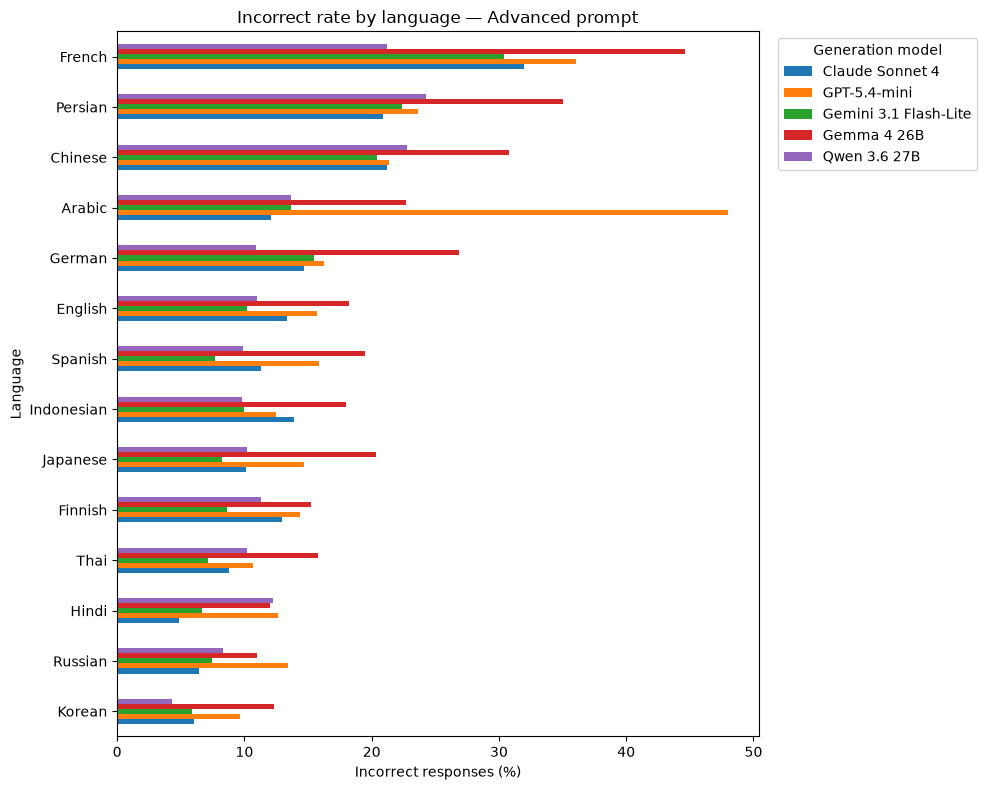

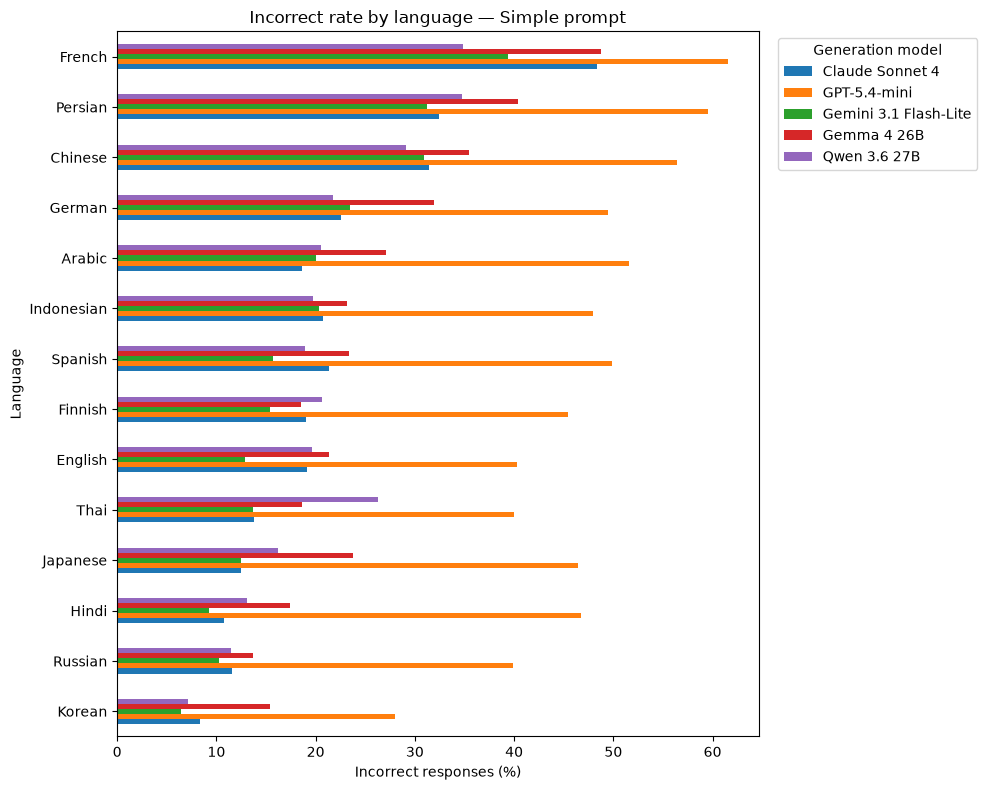

In [22]:
language_aggregate = add_percentage_columns(
    grouped_bootstrap_rates(
        analysis_df[analysis_df["context_mode_clean"] == "distractor"],
        ["generation_model_clean", "prompt_variant_clean", "language", "language_name"],
        labels=["INCORRECT"],
    )
)

for prompt in sorted(language_aggregate["prompt_variant_clean"].unique()):
    plot_data = language_aggregate[
        language_aggregate["prompt_variant_clean"] == prompt
    ].copy()

    pivot = plot_data.pivot(
        index="language_name",
        columns="generation_model_clean",
        values="rate_pct",
    )
    pivot = pivot.loc[pivot.mean(axis=1).sort_values().index]

    ax = pivot.plot(kind="barh", figsize=(10, 8))
    ax.set_xlabel("Incorrect responses (%)")
    ax.set_ylabel("Language")
    ax.set_title(f"Incorrect rate by language — {prompt.capitalize()} prompt")
    ax.legend(title="Generation model", bbox_to_anchor=(1.02, 1), loc="upper left")
    save_figure(f"incorrect_by_language_{prompt}")


Bootstrap groups: 100%|██████████| 30/30 [00:00<00:00, 33.33it/s]


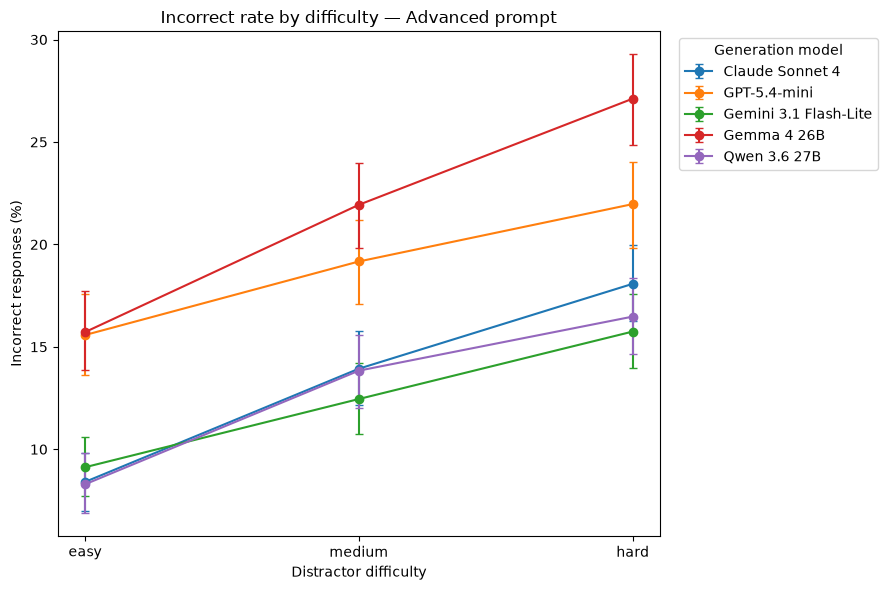

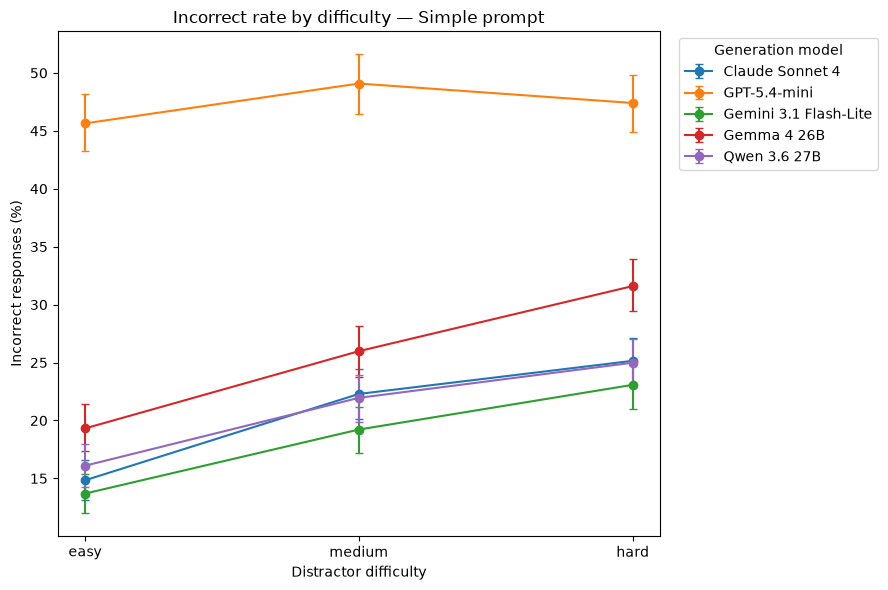

In [23]:
difficulty_groups = [
    "judge_model", "generation_model_clean",
    "prompt_variant_clean", "context_mode_clean", "difficulty_clean",
]

difficulty_ci = add_percentage_columns(
    grouped_bootstrap_rates(
        analysis_df[analysis_df["difficulty_clean"].isin(DIFFICULTY_ORDER)],
        difficulty_groups,
    )
)
difficulty_ci.to_csv(TABLE_DIR / "rates_by_difficulty_with_bootstrap_ci.csv", index=False)

difficulty_aggregate = add_percentage_columns(
    grouped_bootstrap_rates(
        analysis_df[
            (analysis_df["context_mode_clean"] == "distractor")
            & analysis_df["difficulty_clean"].isin(DIFFICULTY_ORDER)
        ],
        ["generation_model_clean", "prompt_variant_clean", "difficulty_clean"],
        labels=["INCORRECT"],
    )
)

for prompt in sorted(difficulty_aggregate["prompt_variant_clean"].unique()):
    plot_data = difficulty_aggregate[
        difficulty_aggregate["prompt_variant_clean"] == prompt
    ]

    plt.figure(figsize=(9, 6))
    for model, group in plot_data.groupby("generation_model_clean"):
        group = group.set_index("difficulty_clean").reindex(DIFFICULTY_ORDER).reset_index()
        y = group["rate_pct"].to_numpy()
        lower = y - group["ci_low_pct"].to_numpy()
        upper = group["ci_high_pct"].to_numpy() - y

        plt.errorbar(
            DIFFICULTY_ORDER, y,
            yerr=np.vstack([lower, upper]),
            marker="o", capsize=3, label=model,
        )

    plt.xlabel("Distractor difficulty")
    plt.ylabel("Incorrect responses (%)")
    plt.title(f"Incorrect rate by difficulty — {prompt.capitalize()} prompt")
    plt.legend(title="Generation model", bbox_to_anchor=(1.02, 1), loc="upper left")
    save_figure(f"incorrect_by_difficulty_{prompt}")


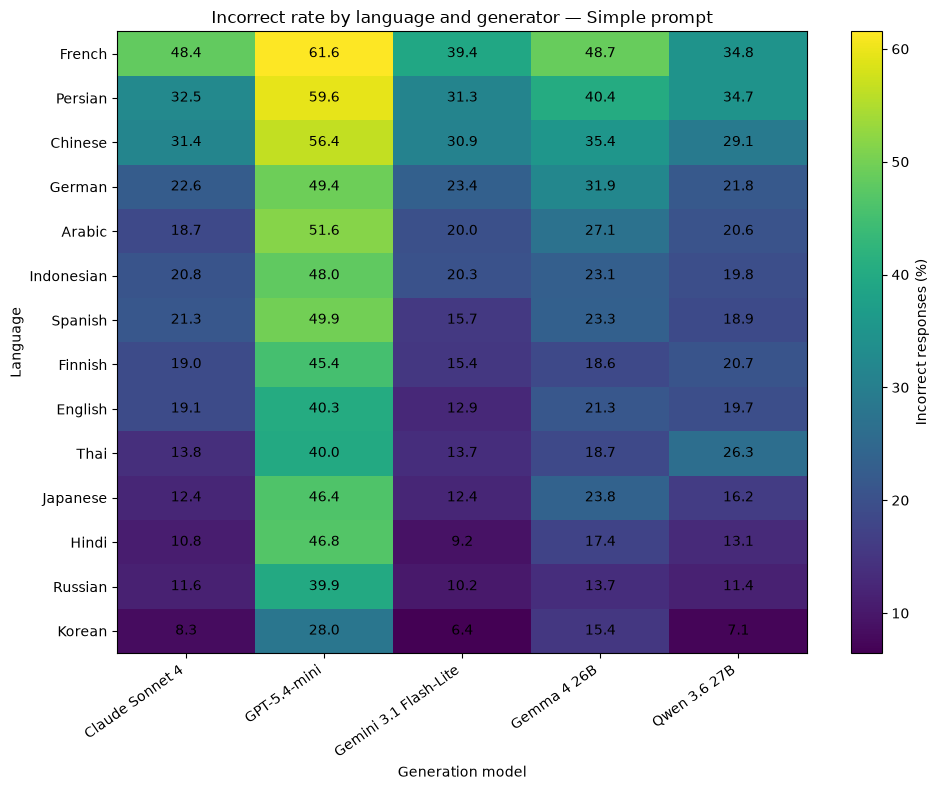

In [24]:
heatmap_data = (
    language_aggregate[
        language_aggregate["prompt_variant_clean"] == "simple"
    ]
    .pivot_table(
        index="language_name",
        columns="generation_model_clean",
        values="rate_pct",
        aggfunc="first",
    )
)

heatmap_data = heatmap_data.loc[
    heatmap_data.mean(axis=1).sort_values(ascending=False).index
]

fig, ax = plt.subplots(figsize=(10, 8))
image = ax.imshow(heatmap_data.to_numpy(), aspect="auto")

ax.set_xticks(np.arange(len(heatmap_data.columns)))
ax.set_xticklabels(heatmap_data.columns, rotation=35, ha="right")
ax.set_yticks(np.arange(len(heatmap_data.index)))
ax.set_yticklabels(heatmap_data.index)

for i in range(heatmap_data.shape[0]):
    for j in range(heatmap_data.shape[1]):
        ax.text(j, i, f"{heatmap_data.iloc[i, j]:.1f}", ha="center", va="center")

fig.colorbar(image, ax=ax, label="Incorrect responses (%)")
ax.set_title("Incorrect rate by language and generator — Simple prompt")
ax.set_xlabel("Generation model")
ax.set_ylabel("Language")
save_figure("heatmap_language_generator_incorrect_simple")


In [25]:
def paired_prompt_effect(
    df: pd.DataFrame,
    target_label: str = "INCORRECT",
    n_boot: int = N_BOOTSTRAP,
    seed: int = RANDOM_SEED,
) -> dict[str, float]:
    work = df[df["prompt_variant_clean"].isin(["simple", "advanced"])].copy()
    work["is_target"] = (work["judge_label_clean"] == target_label).astype(float)

    per_query = (
        work.groupby([CLUSTER_COL, "prompt_variant_clean"])["is_target"]
        .mean()
        .unstack("prompt_variant_clean")
        .dropna(subset=["simple", "advanced"])
    )

    if per_query.empty:
        return {
            "n_clusters": 0, "difference": np.nan,
            "ci_low": np.nan, "ci_high": np.nan,
            "probability_reduction": np.nan,
        }

    diffs = (per_query["advanced"] - per_query["simple"]).to_numpy()
    rng = np.random.default_rng(seed)
    boot = np.empty(n_boot)

    for b in range(n_boot):
        sampled = rng.integers(0, len(diffs), size=len(diffs))
        boot[b] = diffs[sampled].mean()

    return {
        "n_clusters": len(diffs),
        "difference": float(diffs.mean()),
        "ci_low": float(np.quantile(boot, 0.025)),
        "ci_high": float(np.quantile(boot, 0.975)),
        "probability_reduction": float((boot < 0).mean()),
    }


effect_rows = []
effect_groups = [
    "judge_model", "generation_model_clean",
    "context_mode_clean", "language",
]

for values, group in tqdm(
    analysis_df.groupby(effect_groups, dropna=False),
    desc="Paired prompt effects",
):
    effect_rows.append({
        **dict(zip(effect_groups, values)),
        **paired_prompt_effect(group),
    })

prompt_effects = pd.DataFrame(effect_rows)
prompt_effects["difference_pp"] = 100 * prompt_effects["difference"]
prompt_effects["ci_low_pp"] = 100 * prompt_effects["ci_low"]
prompt_effects["ci_high_pp"] = 100 * prompt_effects["ci_high"]

prompt_effects.to_csv(
    TABLE_DIR / "advanced_minus_simple_incorrect_rate.csv",
    index=False,
)

display(prompt_effects.sort_values("difference_pp").head(30))


Paired prompt effects: 100%|██████████| 294/294 [00:03<00:00, 75.92it/s]


,judge_model,generation_model_clean,context_mode_clean,language,n_clusters,difference,ci_low,ci_high,probability_reduction,difference_pp,ci_low_pp,ci_high_pp
18,GPT-5.4-mini,GPT-5.4-mini,distractor,fa,100,-0.390000,-0.440000,-0.333333,1.0,-39.000000,-44.000000,-33.333333
120,Gemini 3.1 Flash-Lite,GPT-5.4-mini,distractor,id,100,-0.370000,-0.430000,-0.310000,1.0,-37.000000,-43.000000,-31.000000
115,Gemini 3.1 Flash-Lite,GPT-5.4-mini,distractor,es,100,-0.360000,-0.416667,-0.303333,1.0,-36.000000,-41.666667,-30.333333
218,Qwen 3.6 27B,GPT-5.4-mini,distractor,id,100,-0.356667,-0.416667,-0.300000,1.0,-35.666667,-41.666667,-30.000000
113,Gemini 3.1 Flash-Lite,GPT-5.4-mini,distractor,de,100,-0.353333,-0.416667,-0.293333,1.0,-35.333333,-41.666667,-29.333333
21,GPT-5.4-mini,GPT-5.4-mini,distractor,hi,100,-0.353333,-0.416667,-0.293333,1.0,-35.333333,-41.666667,-29.333333
27,GPT-5.4-mini,GPT-5.4-mini,distractor,zh,100,-0.353333,-0.423333,-0.283333,1.0,-35.333333,-42.333333,-28.333333
116,Gemini 3.1 Flash-Lite,GPT-5.4-mini,distractor,fa,100,-0.353333,-0.406667,-0.293333,1.0,-35.333333,-40.666667,-29.333333
125,Gemini 3.1 Flash-Lite,GPT-5.4-mini,distractor,zh,100,-0.350000,-0.413333,-0.286583,1.0,-35.000000,-41.333333,-28.658333
223,Qwen 3.6 27B,GPT-5.4-mini,distractor,zh,100,-0.350000,-0.413417,-0.283333,1.0,-35.000000,-41.341667,-28.333333


In [ ]:
agreement_keys = [
    c for c in [
        "language", "query_id", "distractor_id",
        "generation_model_clean", "prompt_variant_clean", "context_mode_clean",
    ]
    if c in analysis_df.columns
]

judge_wide = (
    analysis_df.pivot_table(
        index=agreement_keys,
        columns="judge_model",
        values="judge_label_clean",
        aggfunc="first",
    )
    .reset_index()
)

judge_names = sorted(analysis_df["judge_model"].unique())
agreement_rows = []

for i, judge_a in enumerate(judge_names):
    for judge_b in judge_names[i + 1:]:
        pair = judge_wide[[judge_a, judge_b]].dropna()
        if pair.empty:
            continue

        agreement_rows.append({
            "judge_a": judge_a,
            "judge_b": judge_b,
            "n": len(pair),
            "exact_agreement": (pair[judge_a] == pair[judge_b]).mean(),
            "cohen_kappa": cohen_kappa_score(
                pair[judge_a], pair[judge_b], labels=VALID_LABELS
            ),
        })

        matrix = pd.DataFrame(
            confusion_matrix(
                pair[judge_a], pair[judge_b], labels=VALID_LABELS
            ),
            index=[f"{judge_a}: {x}" for x in VALID_LABELS],
            columns=[f"{judge_b}: {x}" for x in VALID_LABELS],
        )

        safe_a = re.sub(r"[^a-z0-9]+", "_", judge_a.lower()).strip("_")
        safe_b = re.sub(r"[^a-z0-9]+", "_", judge_b.lower()).strip("_")
        matrix.to_csv(TABLE_DIR / f"confusion_{safe_a}_vs_{safe_b}.csv")

judge_agreement = pd.DataFrame(agreement_rows)
judge_agreement.to_csv(TABLE_DIR / "pairwise_judge_agreement.csv", index=False)
display(judge_agreement)


,judge_a,judge_b,n,exact_agreement,cohen_kappa
0,GPT-5.4-mini,Gemini 3.1 Flash-Lite,58800,0.948707,0.912220
1,GPT-5.4-mini,Qwen 3.6 27B,58757,0.952772,0.918511
2,Gemini 3.1 Flash-Lite,Qwen 3.6 27B,58757,0.962370,0.935176


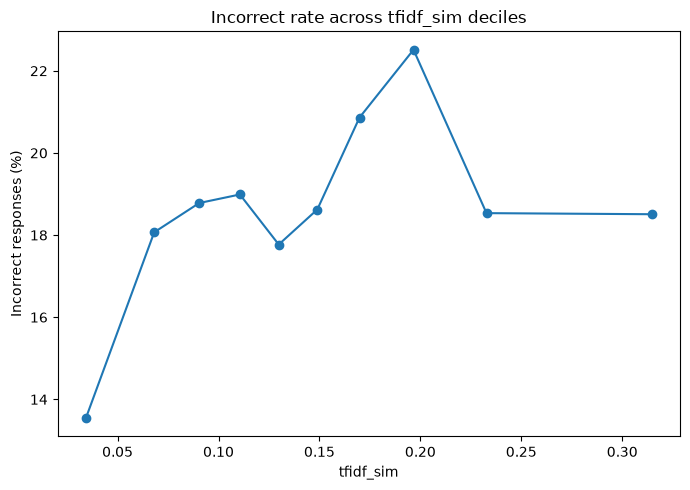

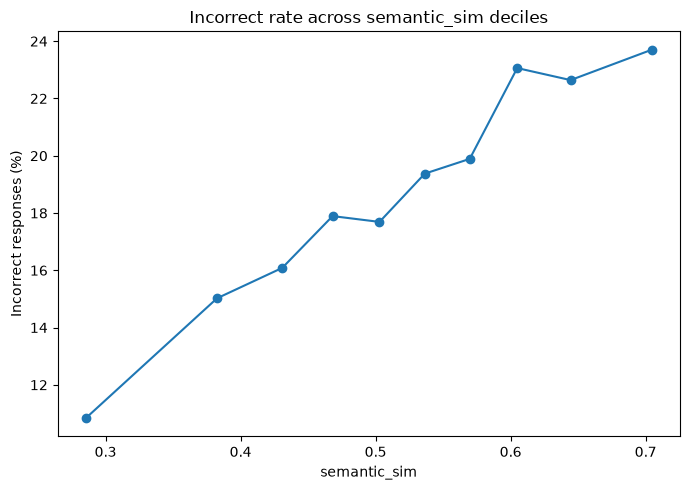

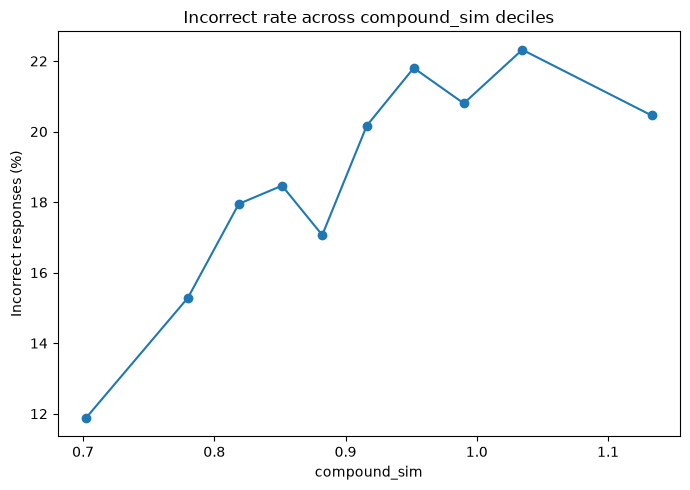

In [26]:
similarity_cols = [
    c for c in ["tfidf_sim", "semantic_sim", "compound_sim"]
    if c in analysis_df.columns
]

similarity_tables = []

for similarity_col in similarity_cols:
    work = analysis_df[[similarity_col, "judge_label_clean"]].dropna().copy()
    work["is_incorrect"] = (work["judge_label_clean"] == "INCORRECT").astype(int)
    work["bin"] = pd.qcut(work[similarity_col], q=10, duplicates="drop")

    table = (
        work.groupby("bin", observed=True)
        .agg(
            similarity_mean=(similarity_col, "mean"),
            incorrect_rate=("is_incorrect", "mean"),
            n=("is_incorrect", "size"),
        )
        .reset_index(drop=True)
    )
    table["similarity_metric"] = similarity_col
    similarity_tables.append(table)

    plt.figure(figsize=(7, 5))
    plt.plot(
        table["similarity_mean"],
        100 * table["incorrect_rate"],
        marker="o",
    )
    plt.xlabel(similarity_col)
    plt.ylabel("Incorrect responses (%)")
    plt.title(f"Incorrect rate across {similarity_col} deciles")
    save_figure(f"incorrect_by_{similarity_col}_decile")

similarity_summary = pd.concat(similarity_tables, ignore_index=True)
similarity_summary.to_csv(
    TABLE_DIR / "incorrect_rate_by_similarity_decile.csv",
    index=False,
)


In [27]:
paper_language = add_percentage_columns(
    grouped_bootstrap_rates(
        analysis_df,
        ["generation_model_clean", "context_mode_clean", "language", "language_name"],
        labels=["INCORRECT"],
    )
)
paper_language["incorrect_rate_ci"] = paper_language["rate_ci"]

paper_language_table = paper_language.pivot_table(
    index=["language", "language_name"],
    columns=["context_mode_clean", "generation_model_clean"],
    values="incorrect_rate_ci",
    aggfunc="first",
)

paper_language_table.to_csv(TABLE_DIR / "paper_language_incorrect_table.csv")
(TABLE_DIR / "paper_language_incorrect_table.tex").write_text(
    paper_language_table.to_latex(
        escape=True,
        caption="Incorrect-response rates by language with 95\\% cluster-bootstrap confidence intervals.",
        label="tab:incorrect-by-language",
    ),
    encoding="utf-8",
)

paper_difficulty = add_percentage_columns(
    grouped_bootstrap_rates(
        analysis_df,
        ["generation_model_clean", "prompt_variant_clean",
         "context_mode_clean", "difficulty_clean"],
        labels=["INCORRECT"],
    )
)
paper_difficulty["incorrect_rate_ci"] = paper_difficulty["rate_ci"]

paper_difficulty_table = (
    paper_difficulty.pivot_table(
        index=["generation_model_clean", "prompt_variant_clean", "context_mode_clean"],
        columns="difficulty_clean",
        values="incorrect_rate_ci",
        aggfunc="first",
    )
    .reindex(columns=DIFFICULTY_ORDER)
    .reset_index()
)

paper_difficulty_table.to_csv(
    TABLE_DIR / "paper_difficulty_incorrect_table.csv",
    index=False,
)
(TABLE_DIR / "paper_difficulty_incorrect_table.tex").write_text(
    paper_difficulty_table.to_latex(
        index=False,
        escape=True,
        caption="Incorrect-response rates by distractor difficulty with 95\\% cluster-bootstrap confidence intervals.",
        label="tab:incorrect-by-difficulty",
    ),
    encoding="utf-8",
)

display(paper_language_table)
display(paper_difficulty_table)


Bootstrap groups: 100%|██████████| 42/42 [00:01<00:00, 32.42it/s]


context_mode_clean             distractor                     \
generation_model_clean    Claude Sonnet 4       GPT-5.4-mini   
language language_name                                         
ar       Arabic         15.4 [10.9, 20.1]  49.8 [44.1, 55.4]   
de       German         18.6 [14.3, 23.3]  32.8 [28.4, 37.8]   
en       English        16.2 [11.6, 20.9]  28.0 [22.8, 32.9]   
es       Spanish        16.3 [12.3, 20.6]  32.9 [28.0, 37.9]   
fa       Persian        26.7 [22.1, 31.5]  41.6 [36.8, 46.5]   
fi       Finnish        16.0 [12.1, 20.4]  29.8 [25.5, 34.8]   
fr       French         40.2 [34.1, 46.5]  48.8 [43.3, 54.3]   
hi       Hindi            7.8 [5.2, 10.8]  29.7 [25.2, 34.3]   
id       Indonesian     17.3 [12.8, 22.2]  30.2 [25.7, 34.9]   
ja       Japanese        11.3 [8.1, 14.9]  30.6 [26.1, 34.9]   
ko       Korean           7.2 [4.4, 10.2]  18.8 [15.1, 22.9]   
ru       Russian          9.0 [5.8, 12.4]  26.7 [22.0, 31.6]   
th       Thai            11.3 [7.6, 15.7]  25.3 [21.4, 29.1]   
zh       Chinese        26.3 [21.4, 31.6]  38.9 [33.9, 43.8]   

context_mode_clean                                               \
generation_model_clean Gemini 3.1 Flash-Lite        Gemma 4 26B   
language language_name                                            
ar       Arabic            16.8 [12.1, 21.9]  24.9 [19.6, 30.6]   
de       German            19.4 [15.1, 24.5]  29.4 [23.9, 35.3]   
en       English            11.6 [8.0, 15.5]  19.8 [14.5, 24.9]   
es       Spanish            11.7 [8.3, 15.3]  21.4 [16.6, 26.5]   
fa       Persian           26.8 [22.0, 32.3]  37.7 [32.3, 43.4]   
fi       Finnish            12.1 [8.6, 15.8]  16.9 [13.3, 20.7]   
fr       French            34.9 [28.8, 41.1]  46.7 [40.1, 53.3]   
hi       Hindi               7.9 [5.2, 10.9]  14.7 [11.1, 18.7]   
id       Indonesian        15.2 [11.2, 19.4]  20.6 [15.8, 25.6]   
ja       Japanese           10.3 [6.9, 14.2]  22.1 [17.1, 27.3]   
ko       Korean               6.2 [3.6, 8.9]  13.9 [10.2, 17.7]   
ru       Russian             8.8 [5.6, 12.4]   12.3 [8.6, 16.3]   
th       Thai               10.4 [7.3, 14.1]  17.2 [13.1, 21.7]   
zh       Chinese           25.7 [20.7, 31.1]  33.1 [27.1, 39.4]   

context_mode_clean                        distractor_plus_gold  \
generation_model_clean       Qwen 3.6 27B          Gemma 4 26B   
language language_name                                           
ar       Arabic         17.1 [13.2, 21.4]       6.8 [4.0, 9.8]   
de       German         16.3 [12.7, 20.5]    15.8 [11.7, 20.4]   
en       English        15.3 [11.0, 20.1]     12.9 [8.8, 17.5]   
es       Spanish        14.4 [10.9, 17.9]    19.6 [14.8, 24.5]   
fa       Persian        29.5 [24.4, 35.2]    19.1 [14.7, 23.7]   
fi       Finnish        16.0 [12.1, 20.4]      8.7 [5.7, 12.2]   
fr       French         28.0 [23.0, 33.2]    26.5 [21.3, 32.0]   
hi       Hindi           12.7 [9.1, 16.6]     13.4 [9.0, 18.1]   
id       Indonesian     14.8 [10.7, 19.2]    16.4 [11.7, 21.6]   
ja       Japanese        13.2 [9.3, 17.2]     10.8 [6.8, 15.2]   
ko       Korean            5.7 [3.4, 8.1]      9.3 [5.8, 12.9]   
ru       Russian          9.9 [6.8, 13.2]      9.5 [5.7, 14.1]   
th       Thai           18.3 [14.6, 22.2]       4.2 [2.2, 6.6]   
zh       Chinese        25.9 [20.7, 31.4]    17.6 [12.6, 22.9]   

context_mode_clean                         
generation_model_clean       Qwen 3.6 27B  
language language_name                     
ar       Arabic            5.4 [2.9, 7.9]  
de       German          10.9 [7.6, 14.6]  
en       English          9.3 [5.9, 13.3]  
es       Spanish         13.4 [9.6, 17.6]  
fa       Persian        17.0 [12.6, 21.8]  
fi       Finnish          9.8 [6.5, 13.5]  
fr       French         19.8 [15.2, 24.7]  
hi       Hindi            7.9 [5.1, 10.9]  
id       Indonesian      11.4 [8.2, 15.1]  
ja       Japanese          5.8 [2.7, 9.2]  
ko       Korean            4.2 [1.5, 7.4]  
ru       Russian           5.4 [

difficulty_clean,generation_model_clean,prompt_variant_clean,context_mode_clean,easy,medium,hard
0,Claude Sonnet 4,advanced,distractor,"8.4 [7.0, 9.8]","13.9 [12.1, 15.8]","18.1 [16.3, 20.0]"
1,Claude Sonnet 4,simple,distractor,"14.8 [13.1, 16.6]","22.3 [20.2, 24.4]","25.1 [23.0, 27.1]"
2,GPT-5.4-mini,advanced,distractor,"15.6 [13.6, 17.6]","19.2 [17.1, 21.2]","22.0 [19.8, 24.0]"
3,GPT-5.4-mini,simple,distractor,"45.6 [43.2, 48.2]","49.1 [46.4, 51.6]","47.4 [44.9, 49.8]"
4,Gemini 3.1 Flash-Lite,advanced,distractor,"9.1 [7.7, 10.6]","12.5 [10.7, 14.2]","15.7 [14.0, 17.6]"
5,Gemini 3.1 Flash-Lite,simple,distractor,"13.7 [12.0, 15.4]","19.2 [17.2, 21.2]","23.1 [21.0, 25.2]"
6,Gemma 4 26B,advanced,distractor,"15.7 [13.9, 17.7]","21.9 [19.8, 24.0]","27.1 [24.9, 29.3]"
7,Gemma 4 26B,advanced,distractor_plus_gold,"11.5 [10.0, 13.0]","13.5 [11.9, 15.1]","14.6 [12.9, 16.3]"
8,Gemma 4 26B,simple,distractor,"19.3 [17.3, 21.4]","26.0 [23.8, 28.1]","31.6 [29.4, 33.9]"
9,Gemma 4 26B,simple,distractor_plus_gold,"11.7 [10.2, 13.2]","13.9 [12.4, 15.6]","16.3 [14.6, 18.1]"
